# ML Mini-project - Titanic survival prediction

**Problem statement:** build a machine learning model that predicts which passengers survived the Titanic shipwreck from passenger data (name, age, gender, socio-economic class, fare, family size, ...). Clean the data, engineer features, train Logistic Regression and Random Forest, and compare accuracy and confusion matrices.

**Libraries used:** pandas, numpy (data), seaborn/matplotlib (plots), scikit-learn (models, metrics).

**Driver:** the Kaggle *Titanic* `train.csv` is not available offline, so a seeded synthetic table with the same 12 columns is generated (survival depends on sex, class and age, as in the real data). To use the real file set `CSV_PATH = "train.csv"`. No input is taken at runtime.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split

CSV_PATH = None  # e.g. "train.csv"

## 1. Load the data

In [2]:
def make_data(n=891, seed=11):
    rng = np.random.default_rng(seed)
    sex = rng.choice(["male", "female"], n, p=[0.64, 0.36])
    pclass = rng.choice([1, 2, 3], n, p=[0.24, 0.21, 0.55])
    age = rng.normal(30, 14, n).clip(1, 80).round()
    title = np.where(sex == "female", rng.choice(["Mrs", "Miss"], n), np.where(age < 13, "Master", "Mr"))
    score = -0.5 + 2.8 * (sex == "female") - 1.0 * (pclass - 1) - 0.03 * (age - 30) + 1.2 * (age < 10)
    df = pd.DataFrame({
        "PassengerId": np.arange(1, n + 1), "Survived": (rng.random(n) < 1 / (1 + np.exp(-score))).astype(int),
        "Pclass": pclass, "Name": [f"Person{i}, {t}. X" for i, t in enumerate(title)], "Sex": sex, "Age": age,
        "SibSp": rng.choice([0, 1, 2, 3], n, p=[0.68, 0.23, 0.06, 0.03]),
        "Parch": rng.choice([0, 1, 2], n, p=[0.76, 0.14, 0.10]), "Ticket": [f"T{i}" for i in range(n)],
        "Fare": (np.array([85, 21, 11])[pclass - 1] * rng.lognormal(0, 0.4, n)).round(2),
        "Cabin": np.where(pclass == 1, "C85", None), "Embarked": rng.choice(["S", "C", "Q"], n, p=[0.72, 0.19, 0.09]),
    })
    df.loc[rng.random(n) < 0.2, "Age"] = np.nan  # missing ages, as in the real data
    return df


df = pd.read_csv(CSV_PATH) if CSV_PATH else make_data()
print(df.shape, "| survival rate:", round(df.Survived.mean(), 3))
print("Missing values:", df.isnull().sum()[df.isnull().sum() > 0].to_dict())

(891, 12) | survival rate: 0.356
Missing values: {'Age': 205, 'Cabin': 681}


## 2. Explore: who survived?

{'female': 0.702, 'male': 0.189} (survival rate by sex)
{1: 0.533, 2: 0.428, 3: 0.248} (survival rate by class)


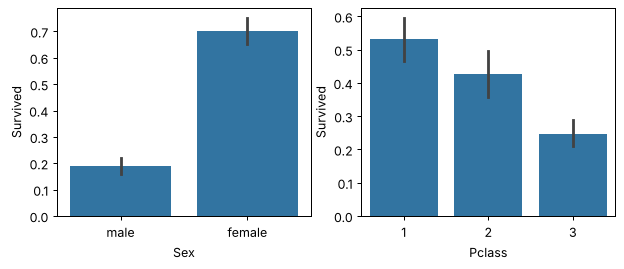

In [3]:
print(df.groupby("Sex").Survived.mean().round(3).to_dict(), "(survival rate by sex)")
print(df.groupby("Pclass").Survived.mean().round(3).to_dict(), "(survival rate by class)")
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
sns.barplot(x="Sex", y="Survived", data=df, ax=axes[0])
sns.barplot(x="Pclass", y="Survived", data=df, ax=axes[1])

## 3. Clean the data and engineer features
Missing ages are filled with the median, `Title` is taken from the name, `FamilySize` combines SibSp and Parch, and categorical columns are one-hot encoded. `Cabin`, `Ticket` and `PassengerId` are dropped.

In [4]:
data = df.copy()
data["Age"] = data["Age"].fillna(data["Age"].median())
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])
data["Title"] = data["Name"].str.extract(r",\s*([^\.]+)\.")[0].str.strip()
data["Title"] = data["Title"].where(data["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Other")
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
X = pd.get_dummies(data[["Pclass", "Sex", "Age", "Fare", "FamilySize", "Embarked", "Title"]], drop_first=True)
y = data["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print("Features used:", list(X.columns))

Features used: ['Pclass', 'Age', 'Fare', 'FamilySize', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs']


## 4. Train and compare the models

In [5]:
models = {"Logistic Regression": LogisticRegression(max_iter=1000),
          "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=5, random_state=42)}
preds = {}
for name, model in models.items():
    preds[name] = model.fit(X_train, y_train).predict(X_test)
    print(f"{name}: accuracy = {accuracy_score(y_test, preds[name]):.3f}")
    print("  confusion matrix [[TN FP] [FN TP]]:", confusion_matrix(y_test, preds[name]).tolist())

Logistic Regression: accuracy = 0.803
  confusion matrix [[TN FP] [FN TP]]: [[129, 15], [29, 50]]
Random Forest: accuracy = 0.803
  confusion matrix [[TN FP] [FN TP]]: [[124, 20], [24, 55]]


## 5. Which features matter most?

Title_Mr      0.247
Sex_male      0.218
Fare          0.160
Age           0.117
Pclass        0.111
Title_Miss    0.059


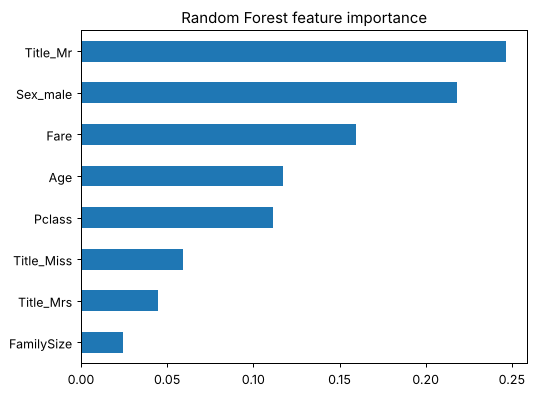

In [6]:
importance = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values()
print(importance.sort_values(ascending=False).head(6).round(3).to_string())
importance.tail(8).plot(kind="barh", title="Random Forest feature importance")

**Conclusion:** sex, passenger class and age are the strongest predictors of survival ("women and children first", and first-class passengers had better access to lifeboats). Compare the accuracy of the two models above to choose the better one.